In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("C:\ML\data\diabetic_data.csv ")



df = pd.read_csv(DATA_DIR).replace("?", np.nan)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [12]:
from sklearn.model_selection import GroupShuffleSplit

# 1 if readmitted within 30 days, 0 otherwise
y = (df["readmitted"] == "<30").astype(int)

# Patient IDs are only there to split the data
groups = df["patient_nbr"]

# Remove response, IDs and very sparse weight variable
X = df.drop(
    columns=[
        "readmitted",
        
        "encounter_id",
        "patient_nbr",
        "weight"
    ]
)

# Turn administrative ID codes into categorical variables
id_columns = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]
for col in id_columns:
    X[col] = X[col].astype("object")

# Split into groups of 80/20
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)
train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining positive rate:", round(y_train.mean(), 4))
print("Testing positive rate:", round(y_test.mean(), 4))

print(
    "\nPatient overlap:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)

Training rows: 81613
Testing rows: 20153

Training positive rate: 0.1128
Testing positive rate: 0.1067

Patient overlap: 0


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Select categorical and numerical features
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

# Preprocessing numerical data
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing categorical data
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])


# Combining preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Main Baseline Model
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        penalty="l2",
        C=1.0,
        class_weight="balanced",
        max_iter=800,
        random_state=42
    ))
])

print("Preprocessing pipeline and Logistic Regression created.")

Numerical features: 8
Categorical features: 38
Preprocessing pipeline and Logistic Regression created.


C:\Users\NEWLYN DABREO\AppData\Local\Temp\ipykernel_29348\3397478280.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [14]:
# Training Dummy Classifier
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

# Training Logistic Regression with preprocessing.
print("Training Logistic Regression...")

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Training Logistic Regression...


c:\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Logistic Regression training completed!


In [15]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve
)
dummy_probs = dummy_model.predict_proba(X_test)[:, 1]
logistic_probs = logistic_model.predict_proba(X_test)[:, 1]

def evaluate_model(name, y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    eligible = np.where(precision[:-1] >= 0.60)[0]
    recall_at_precision_60 = (
        float(recall[eligible].max()) if len(eligible) else np.nan
    )

    return {
        "Model": name,
        "PR-AUC (Average Precision)": average_precision_score(
            y_true, probabilities
        ),
        "Recall at Precision >= 0.60": recall_at_precision_60,
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

results = pd.DataFrame([
    evaluate_model("Dummy Classifier", y_test, dummy_probs),
    evaluate_model("L2 Logistic Regression", y_test, logistic_probs)
])

display(results.round(4))

,Model,PR-AUC (Average Precision),Recall at Precision >= 0.60,ROC-AUC
0,Dummy Classifier,0.1067,NaN,0.5000
1,L2 Logistic Regression,0.2023,0.0023,0.6579


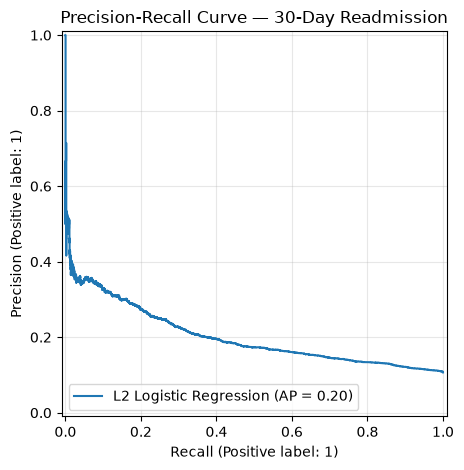

In [16]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    logistic_probs,
    name="L2 Logistic Regression"
)
plt.title("Precision-Recall Curve — 30-Day Readmission")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

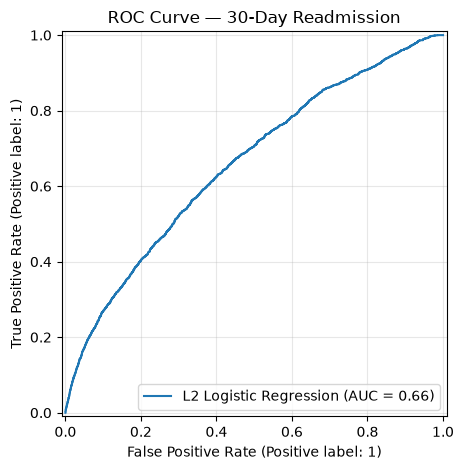

In [17]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    logistic_probs,
    name="L2 Logistic Regression"
)
plt.title("ROC Curve — 30-Day Readmission")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()